# 21 · Farm detection from behaviour (work package 10)

**Work package 10** of the [applications plan](../../research/implementation_plan_applications.md), section 10.
A farm is a group of accounts that act as one: they pick up the same tokens at nearly the same moments. Notebook 11
found one kind, accounts with exactly the same 14-day token set. This notebook looks for groups from timing.

- **Co-action graph:** two accounts are linked when at least $m$ of the tokens they first-traded in a window were
  first-traded by both within $\Delta$ minutes of each other. "First trade" is the account's first trade of the
  token anywhere in the data.
- **Groups:** connected components; a component of more than 500 accounts is split into Louvain communities.
- **Check without labels (10.2):** a real group keeps acting together on data it was not built from. Its
  co-action rate on a later window (of its member pairs that both first-trade something there, the share that
  first-trade a common token within $\Delta$) is compared with that of matched random pairs (accounts with the same
  number of first trades and the same first day, also active later).
- **Success criterion (stated in the plan):** the median group's rate on Dev B is at least 10 times the matched
  rate, and the lower end of a bootstrap interval over groups is above 10.

| Step | Build window | Later window |
| --- | --- | --- |
| Choose $\Delta$, $m$ | Dev A first half, 2 – 12 July | Dev A second half, 12 – 22 July |
| Check | Dev A, 2 – 22 July | Dev B, 22 July – 13 August |
| Report | Dev A + Dev B, 2 July – 13 August | test, 13 August – 10 September |

The choice rule (`project_direction.md`, 24 November): among the settings that pass the check on the Dev A split,
the one with the most grouped accounts. **Privacy:** results are in aggregate; no account is listed.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import farms as fm
import plots
import protocol as pc
import stats
import token_data as td

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
legs = td.load_legs()
DEV_A, SPLIT, DEV_B, TEST, END = (pd.Timestamp(d, tz="UTC") for d in ["2026-07-02", "2026-07-12", "2026-07-22", "2026-08-13", "2026-09-10"])

## 1. First trades per window

How many first trades each window holds, and how many of the accounts with a first trade in one window have one
in the next. A group can only be checked through the members that come back.

In [2]:
first = {
    "dev_a_first_half": fm.first_trades(legs, DEV_A, SPLIT),
    "dev_a_second_half": fm.first_trades(legs, SPLIT, DEV_B),
    "dev_a": fm.first_trades(legs, DEV_A, DEV_B),
    "dev_b": fm.first_trades(legs, DEV_B, TEST),
    "dev_a_b": fm.first_trades(legs, DEV_A, TEST),
    "test": fm.first_trades(legs, TEST, END),
}
pd.DataFrame({name: {"first_trades": len(f), "accounts": f["user"].nunique(), "tokens": f["token"].nunique()} for name, f in first.items()}).T

,first_trades,accounts,tokens
dev_a_first_half,218877,111105,14554
dev_a_second_half,147900,72508,13415
dev_a,366777,171961,22267
dev_b,387398,153716,19414
dev_a_b,754175,303178,32966
test,604475,230815,33486


In [3]:
for build, later in [("dev_a_first_half", "dev_a_second_half"), ("dev_a", "dev_b"), ("dev_a_b", "test")]:
    share = first[build]["user"].drop_duplicates().isin(first[later]["user"]).mean()
    print(f"Accounts of {build} with a first trade in {later}: {share:.1%}")

Accounts of dev_a_first_half with a first trade in dev_a_second_half: 10.5%
Accounts of dev_a with a first trade in dev_b: 13.1%
Accounts of dev_a_b with a first trade in test: 12.7%


## 2. Choosing $\Delta$ and $m$ on Dev A

For each of the 9 settings: groups built on the first half, checked on the second half. `accounts` is the number of
grouped accounts; `checked` the groups with at least two members active in the second half.

In [4]:
rows, tables = [], {}
for delta in fm.DELTAS_MINUTES:
    for m in fm.MIN_SHARED:
        group_of = fm.groups(fm.coaction_edges(first["dev_a_first_half"], delta, m))
        summary, per_group = fm.check(group_of, first["dev_a_first_half"], first["dev_a_second_half"], delta)
        rows.append({"delta": delta, "min_shared": m, "accounts": len(group_of), "groups": group_of.nunique(), **summary})
        tables[(delta, m)] = per_group
grid = pd.DataFrame(rows)
grid[["delta", "min_shared", "accounts", "groups", "groups_checked", "median_group_rate", "matched_rate", "ratio", "ratio_low", "ratio_high", "success"]]

,delta,min_shared,accounts,groups,groups_checked,median_group_rate,matched_rate,ratio,ratio_low,ratio_high,success
0,5,2,8384,755,126,0.000,0.016,0.000,0.000,0.000,False
1,5,3,3015,255,85,0.333,0.017,19.310,4.499,45.831,False
2,5,5,771,67,41,1.000,0.010,96.885,36.894,199.920,True
3,30,2,11227,884,126,0.000,0.033,0.000,0.000,0.000,False
4,30,3,4077,225,89,0.333,0.038,8.659,0.000,21.491,False
5,30,5,992,83,53,1.000,0.042,23.629,8.353,84.246,False
6,120,2,13722,840,112,0.000,0.029,0.000,0.000,0.045,False
7,120,3,4752,227,68,0.183,0.049,3.770,0.000,18.932,False
8,120,5,1192,92,57,0.667,0.063,10.665,3.751,26.345,False


In [5]:
chosen = fm.choose_setting(grid)
assert chosen is not None, "no setting passes the check on the Dev A split"
DELTA, M = int(chosen["delta"]), int(chosen["min_shared"])
print(f"Chosen setting: delta = {DELTA} minutes, m = {M} shared first trades ({int(chosen['accounts']):,} accounts on the first half).")

Chosen setting: delta = 5 minutes, m = 5 shared first trades (771 accounts on the first half).


**By group size** on the Dev A split, for every setting: the median rate of the groups and the rate of their matched
pairs. Small groups (two or three accounts) decide the median.

In [6]:
def by_size(per_group: pd.DataFrame) -> pd.DataFrame:
    """Groups by size band: number, median and mean co-action rate, matched rate."""
    band = pd.cut(per_group["size"], [1, 2, 5, 20, 100, np.inf], labels=["2", "3-5", "6-20", "21-100", ">100"])
    table = per_group.groupby(band, observed=True).agg(
        groups=("rate", "size"), median_rate=("rate", "median"), mean_rate=("rate", "mean"),
        matched_linked=("matched_linked", "sum"), matched_pairs=("matched_pairs", "sum"),
    )  # fmt: skip
    table["matched_rate"] = table.pop("matched_linked") / table.pop("matched_pairs")
    return table


pd.concat({f"delta {d}, m {m}": by_size(t) for (d, m), t in tables.items()}, names=["setting", "size"]).unstack("size")["median_rate"]

size,2,3-5,6-20,21-100,>100
setting,,,,,
"delta 5, m 2",0.000,0.000,0.050,0.581,0.056
"delta 5, m 3",0.000,0.500,0.444,0.600,0.084
"delta 5, m 5",1.000,0.833,0.540,0.059,0.130
"delta 30, m 2",0.000,0.000,0.150,0.523,0.089
"delta 30, m 3",0.000,0.667,0.367,0.907,0.114
"delta 30, m 5",1.000,0.833,1.000,0.892,0.183
"delta 120, m 2",0.000,0.000,0.000,0.198,0.021
"delta 120, m 3",0.000,0.250,0.350,0.836,0.189
"delta 120, m 5",0.000,0.583,1.000,1.000,0.238


## 3. Groups on Dev A with the chosen setting

What the groups look like: size, share of members with a single first trade in the window, tokens shared by at
least half the members, and the median spread (minutes) of the members' first trades of those tokens.

In [7]:
edges_a = fm.coaction_edges(first["dev_a"], DELTA, M)
groups_a = fm.groups(edges_a)
features_a = fm.group_table(groups_a, first["dev_a"], edges_a)
print(f"Dev A: {len(groups_a):,} accounts in {groups_a.nunique():,} groups; largest {features_a['size'].head(5).tolist()}")
features_a.describe().loc[["count", "mean", "50%", "max"]]

Dev A: 1,054 accounts in 105 groups; largest [219, 98, 78, 64, 40]


,group,size,one_token_share,median_tokens,common_tokens,median_spread_minutes
count,105.000,105.000,105.000,105.000,105.000,104.000
mean,52.000,10.038,0.000,48.281,30.324,889.803
50%,52.000,3.000,0.000,15.500,10.000,2.750
max,104.000,219.000,0.000,356.000,335.000,"17,785.800"


## 4. The check on Dev B

Groups built on Dev A, co-action measured on Dev B. This is the success criterion of section 10.2.

In [8]:
summary_b, per_group_b = fm.check(groups_a, first["dev_a"], first["dev_b"], DELTA)
pd.Series(summary_b)

groups_checked          77
members_checked        683
median_group_rate    1.000
matched_rate         0.046
ratio               21.540
ratio_low            9.883
ratio_high          77.246
success              False
dtype: object

In [9]:
by_size(per_group_b)

,groups,median_rate,mean_rate,matched_rate
size,,,,
2,38,1.000,0.763,0.053
3-5,24,1.000,0.771,0.031
6-20,9,0.747,0.717,0.033
21-100,5,1.000,0.889,0.060
>100,1,0.327,0.327,0.010


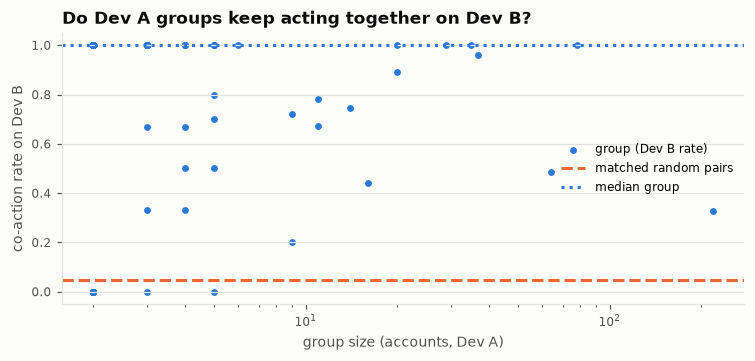

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(per_group_b["size"], per_group_b["rate"], s=12, color=plots.SERIES[0], label="group (Dev B rate)")
ax.axhline(summary_b["matched_rate"], color=plots.SERIES[1], linestyle="--", label="matched random pairs")
ax.axhline(summary_b["median_group_rate"], color=plots.SERIES[0], linestyle=":", label="median group")
ax.set_xscale("log")
ax.set_xlabel("group size (accounts, Dev A)")
ax.set_ylabel("co-action rate on Dev B")
ax.set_title("Do Dev A groups keep acting together on Dev B?")
ax.legend()
plt.show()

## 5. Report on the test period

The same, with groups built on Dev A + Dev B and checked on the test period.

In [11]:
edges_ab = fm.coaction_edges(first["dev_a_b"], DELTA, M)
groups_ab = fm.groups(edges_ab)
summary_test, per_group_test = fm.check(groups_ab, first["dev_a_b"], first["test"], DELTA)
print(f"Dev A + Dev B: {len(groups_ab):,} accounts in {groups_ab.nunique():,} groups")
pd.DataFrame({"dev_b (built on dev_a)": summary_b, "test (built on dev_a_b)": summary_test})

Dev A + Dev B: 2,890 accounts in 234 groups


,dev_b (built on dev_a),test (built on dev_a_b)
groups_checked,77,124
members_checked,683,1737
median_group_rate,1.000,1.000
matched_rate,0.046,0.056
ratio,21.540,17.835
ratio_low,9.883,8.231
ratio_high,77.246,76.301
success,False,False


## 6. Against notebook 11's identical-set rule

Notebook 11's rule: evaluated accounts with exactly the same 14-day token set, at least 20 of them. Its groups at
the Dev A points, compared with the co-action groups built on Dev A:

- **recovered:** at least half of the identical-set group's members are in one co-action group;
- **accounts:** how many accounts each method flags, and how many both flag.

In [12]:
identical = pd.concat([fm.identical_set_members(pc.load_task(legs, t)) for t in pc.POINTS["dev_a"]])
in_coaction = identical.index.isin(groups_a.index)
membership = pd.DataFrame({"set": identical.to_numpy(), "co_group": groups_a.reindex(identical.index).to_numpy()})
recovered = membership.groupby("set")["co_group"].agg(lambda g: g.value_counts().max() >= len(g) / 2 if g.notna().any() else False)
identical_accounts = set(identical.index)
coaction_accounts = set(groups_a.index)
pd.Series({
    "identical-set groups (over the Dev A points)": identical.nunique(),
    "recovered by a co-action group": int(recovered.sum()),
    "accounts flagged by the identical-set rule": len(identical_accounts),
    "accounts flagged by the co-action groups": len(coaction_accounts),
    "flagged by both": len(identical_accounts & coaction_accounts),
})  # fmt: skip

identical-set groups (over the Dev A points)      146
recovered by a co-action group                      7
accounts flagged by the identical-set rule      13222
accounts flagged by the co-action groups         1054
flagged by both                                   207
dtype: int64

## 7. Sensitivity of the project's result (10.3)

The per-account recall of the baseline, the fixed blend and the LambdaMART ranker at the Dev B and test points
(written by `src/scripts/build_farm_sensitivity.py`; the same scores as reported). Recall per point is recomputed
with three sets of accounts removed, every model alike:

- **co-action groups:** members of the chosen groups (built on Dev A for Dev B, on Dev A + Dev B for test);
- **loose graph:** every account in the graph with $\Delta$ = 120 minutes, $m$ = 2 on the same build window (an upper
  bound on what timing-based groups could remove);
- **identical sets:** notebook 11's groups at each point.

This is a sensitivity analysis next to the scored result, never in place of it.

In [13]:
WP10 = td.PROJECT_DIR / "wp10"
MODELS = {"baseline": "popularity (baseline)", "fixed_blend": "fixed blend", "ranker": "ranker: lambdamart"}
per_user = {part: pd.concat([pd.read_parquet(WP10 / f"per_user_{m}_{part}.parquet").assign(model=MODELS[m]) for m in MODELS]) for part in ("dev_b", "test")}
loose = {
    "dev_b": fm.groups(fm.coaction_edges(first["dev_a"], 120, 2)).index,
    "test": fm.groups(fm.coaction_edges(first["dev_a_b"], 120, 2)).index,
}
coaction = {"dev_b": groups_a.index, "test": groups_ab.index}
identical_at = {t: fm.identical_set_members(pc.load_task(legs, t)).index for part in ("dev_b", "test") for t in pc.POINTS[part]}


def removed(part: str, which: str, users: pd.Series, points: pd.Series) -> np.ndarray:
    """Which rows (accounts at points) are removed by the given set."""
    if which == "none":
        return np.zeros(len(users), dtype=bool)
    if which == "co-action groups":
        return users.isin(coaction[part]).to_numpy()
    if which == "loose graph":
        return users.isin(loose[part]).to_numpy()
    out = np.zeros(len(users), dtype=bool)
    for t, members in identical_at.items():
        at = (points == t).to_numpy()
        out[at] = users[at].isin(members).to_numpy()
    return out


rows, compare_tables = [], {}
for part, table in per_user.items():
    for which in ("none", "co-action groups", "loose graph", "identical sets"):
        drop = removed(part, which, table["user"], table["point"])
        kept = table[~drop]
        per_point = {m: g.groupby("point")["recall"].mean().rename("recall").reset_index() for m, g in kept.groupby("model")}
        compare = stats.compare({m: per_point[m] for m in MODELS.values()}, baseline=MODELS["baseline"])
        ranker_vs_blend = stats.paired_differences(per_point[MODELS["ranker"]], per_point[MODELS["fixed_blend"]])
        low, high = stats.bootstrap_over_points(ranker_vs_blend)
        for _, row in compare.iterrows():
            rows.append({"part": part, "removed": which, "removed_share": drop.mean(), "model": row["model"], "recall": row["mean"],
                         "gain_over_baseline": row.get("mean_difference", np.nan), "gain_low": row.get("interval_low", np.nan),
                         "gain_high": row.get("interval_high", np.nan)})  # fmt: skip
        rows.append({"part": part, "removed": which, "removed_share": drop.mean(), "model": "ranker - fixed blend",
                     "gain_over_baseline": ranker_vs_blend.mean(), "gain_low": low, "gain_high": high})  # fmt: skip
sensitivity = pd.DataFrame(rows)
sensitivity.pivot_table(index=["part", "model"], columns="removed", values="gain_over_baseline", sort=False)

removed                     none  co-action groups  loose graph  \
part  model                                                       
dev_b fixed blend          0.049             0.052        0.053   
      ranker: lambdamart   0.052             0.056        0.056   
      ranker - fixed blend 0.004             0.004        0.003   
test  fixed blend          0.044             0.049        0.050   
      ranker: lambdamart   0.046             0.050        0.049   
      ranker - fixed blend 0.001             0.001       -0.001   

removed                     identical sets  
part  model                                 
dev_b fixed blend                    0.048  
      ranker: lambdamart             0.051  
      ranker - fixed blend           0.003  
test  fixed blend                    0.043  
      ranker: lambdamart             0.043  
      ranker - fixed blend           0.000

In [14]:
sensitivity.pivot_table(index=["part", "model"], columns="removed", values="recall", sort=False)

removed                      none  co-action groups  loose graph  \
part  model                                                        
dev_b popularity (baseline) 0.094             0.100        0.119   
      fixed blend           0.142             0.152        0.172   
      ranker: lambdamart    0.146             0.156        0.174   
test  popularity (baseline) 0.108             0.120        0.147   
      fixed blend           0.153             0.169        0.197   
      ranker: lambdamart    0.154             0.170        0.196   

removed                      identical sets  
part  model                                  
dev_b popularity (baseline)           0.092  
      fixed blend                     0.140  
      ranker: lambdamart              0.143  
test  popularity (baseline)           0.101  
      fixed blend                     0.143  
      ranker: lambdamart              0.144

In [15]:
sensitivity[sensitivity["model"] != MODELS["baseline"]].set_index(["part", "removed", "model"])[["removed_share", "gain_over_baseline", "gain_low", "gain_high"]]

removed_share  \
part  removed          model                                 
dev_b none             fixed blend                   0.000   
                       ranker: lambdamart            0.000   
                       ranker - fixed blend          0.000   
      co-action groups fixed blend                   0.074   
                       ranker: lambdamart            0.074   
                       ranker - fixed blend          0.074   
      loose graph      fixed blend                   0.365   
                       ranker: lambdamart            0.365   
                       ranker - fixed blend          0.365   
      identical sets   fixed blend                   0.090   
                       ranker: lambdamart            0.090   
                       ranker - fixed blend          0.090   
test  none             fixed blend                   0.000   
                       ranker: lambdamart            0.000   
                       ranker - fixed blend          0.000   
      co-action groups fixed blend                   0.110   
                       ranker: lambdamart            0.110   
                       ranker - fixed blend          0.110   
      loose graph      fixed blend                   0.404   
                       ranker: lambdamart            0.404   
                       ranker - fixed blend          0.404   
      identical sets   fixed blend                   0.108   
                       ranker: lambdamart            0.108   
                       ranker - fixed blend          0.108   

                                             gain_over_baseline  gain_low  \
part  removed          model                                                
dev_b none             fixed blend                        0.049     0.045   
                       ranker: lambdamart                 0.052     0.047   
                       ranker - fixed blend               0.004    -0.003   
      co-action groups fixed blend                        0.052     0.047   
                       ranker: lambdamart                 0.056     0.050   
                       ranker - fixed blend               0.004    -0.003   
      loose graph      fixed blend                        0.053     0.047   
                       ranker: lambdamart                 0.056     0.050   
                       ranker - fixed blend               0.003    -0.005   
      identical sets   fixed blend                        0.048     0.044   
                       ranker: lambdamart                 0.051     0.046   
                       ranker - fixed blend               0.003    -0.004   
test  none             fixed blend                        0.044     0.039   
                       ranker: lambdamart                 0.046     0.038   
                       ranker - fixed blend               0.001    -0.003   
      co-action groups fixed blend                        0.049     0.042   
                       ranker: lambdamart                 0.050     0.042   
                       ranker - fixed blend               0.001    -0.004   
      loose graph      fixed blend                        0.050     0.042   
                       ranker: lambdamart                 0.049     0.040   
                       ranker - fixed blend              -0.001    -0.005   
      identical sets   fixed blend                        0.043     0.038   
                       ranker: lambdamart                 0.043     0.036   
                       ranker - fixed blend               0.000    -0.004   

                                             gain_high  
part  removed          model                            
dev_b none             fixed blend               0.052  
                       ranker: lambdamart        0.058  
                       ranker - fixed blend      0.012  
      co-action groups fixed blend               0.055  
                       ranker: lambdamart        0.062  
                       ranker 

## 8. What this shows

- **Most farm wallets are used once.** Only 10-13% of the accounts with a first trade in one window have one in
  the next, so most groups can never be checked on later data, by any method.
- **The chosen setting** ($\Delta$ = 5 minutes, $m$ = 5) was the only one to pass on the Dev A split. Settings with
  $m$ = 2 group thousands of accounts that do not act together again (median group rate 0): two shared tokens at
  nearly the same time happen by chance around busy launches.
- **The check on Dev B narrowly fails the criterion.** The groups built on Dev A clearly keep acting together: the
  median group's co-action rate on Dev B is 1.0 (every pair of returning members first-trades a common token within
  5 minutes), against 0.046 for matched random pairs, a ratio of 21.5. But the lower end of the interval over
  groups is 9.9, just below the stated 10. The test report gives the same picture (ratio 17.8, interval 8.2-76).
  As stated, **the success criterion is not met**; the groups are real in the sense that they act together far
  more than chance, but with 77 (Dev B) and 124 (test) checkable groups the evidence does not reach the bar set in
  advance.
- **What the groups look like:** small (median 3 accounts, largest 219), many shared tokens (median 10), and the
  members' first trades of a shared token typically 3 minutes apart. Every member has at least 5 first trades (it
  follows from $m$ = 5), so the "one token" share is 0 by construction and says nothing.
- **A different population from notebook 11's.** Of 146 identical-set groups at the Dev A points, only 7 are
  recovered by a co-action group; the two methods flag 13,222 and 1,054 accounts, with 207 in common. Identical
  sets are mostly accounts with one or two tokens, which the timing rule cannot link (it needs 5 shared first
  trades); the co-action groups are active accounts that move together.
- **The project's result does not come from farms.** Removing the co-action groups (7-11% of evaluated accounts
  at the points), every account in the loose graph (37-40%), or the identical-set groups (9-11%) leaves the
  gain of the fixed blend and of the ranker over popularity at +0.043 to +0.056, with intervals far from zero,
  in Dev B and in test. Removing the timing-based groups even *raises* the gain slightly; removing identical sets
  lowers it by at most 0.003. The ranker against the fixed blend stays near zero (-0.001 to +0.004) in every
  version, as in the scored result. This answers the report's main limitation: coordinated accounts do not
  create the improvement.